In [243]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

from xgboost import XGBRegressor

import joblib


In [244]:
df = pd.DataFrame(pd.read_csv('../data/preprocessed/model_data.csv'))

In [245]:
target_col = "future_rv_20d"

features = [
    "rv_5d",
    "rv_20d",
    "rv_60d",
    "vix_close"
]

required_cols = ["date", target_col] + features
df_train = df[required_cols].dropna().reset_index(drop=True)

print("Dataset shape:", df_train.shape)
print("Date range:", df_train["date"].min(), df["date"].max())

Dataset shape: (3041, 6)
Date range: 2010-01-04 2022-12-30


In [246]:
spy_features = [
    "spy_open", "spy_high", "spy_low", "spy_close",
    "spy_volume", "spy_adj_close", "spy_avg_vol_20d",
    "return", "log_return",
    "return_5d", "return_20d",
    "rv_5d", "rv_20d", "rv_60d",
    "variance_5d", "variance_20d", "variance_60d",
    "drawdown"
]

vix_features = [
    "vix_open", "vix_high", "vix_low", "vix_close",
    "vix_pct_change", "vix_log_return", "vix_daily_return",
    "vix_return_5d", "vix_return_20d", "vix_return_60d",
    "vix_rv_5d", "vix_rv_20d", "vix_rv_60d",
    "vix_variance_5d", "vix_variance_20d",
    "vix_variance_60d",
    "spread", "rolling_corr_20d"
]

options_features = [
    col for col in df.columns
    if (
        col.startswith(("atm_iv_", "put_25_iv_", "call_25_iv_",
                        "rr_25_", "bf_25_"))
        or col in [
            "atm_term_slope_30_90",
            "atm_iv_30d_change_5d"
        ]
    )
]

all_features = spy_features + vix_features + options_features

print("SPY features:", len(spy_features))
print("VIX features:", len(vix_features))
print("Options features:", len(options_features))
print("Total features:", len(all_features))

SPY features: 18
VIX features: 18
Options features: 34
Total features: 70


In [247]:
n = len(df_train)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

horizon = 20

train = df_train.iloc[:train_end - horizon].copy()
val = df_train.iloc[train_end:val_end - horizon].copy()
test = df_train.iloc[val_end:].copy()

In [248]:
sup_features = [
    "rv_5d",
    "rv_20d",
    "rv_60d"
]

X_train_sup = train[sup_features]
y_train = train[target_col]

X_val_sup = val[sup_features]
y_val = val[target_col]

X_test_sup = test[sup_features]

In [249]:
df_ml = df.copy()

df_ml = df_ml.sort_values("date").reset_index(drop=True)

target_col = "future_rv_20d"

# Use the dates from your existing baseline partitions
train_dates = set(train["date"])
val_dates = set(val["date"])
test_dates = set(test["date"])

train_ml = df_ml[df_ml["date"].isin(train_dates)].copy()
val_ml = df_ml[df_ml["date"].isin(val_dates)].copy()
test_ml = df_ml[df_ml["date"].isin(test_dates)].copy()

print("Training observations:", len(train_ml))
print("Validation observations:", len(val_ml))
print("Test observations:", len(test_ml))

Training observations: 2108
Validation observations: 436
Test observations: 457


In [250]:
def qlike(y_true, y_pred, eps=1e-8):
    actual_var = np.maximum(np.asarray(y_true) ** 2, eps)
    predicted_var = np.maximum(np.asarray(y_pred) ** 2, eps)

    return np.mean(
        np.log(predicted_var)
        + actual_var / predicted_var
    )

In [251]:
def evaluate_model(y_true, y_pred, model_name):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        'QLIKE': qlike(y_true, y_pred),
    }

results = []
predictions = {}

Ridge:

In [252]:
ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=100))
])

In [253]:
X_train = train_ml[all_features]
X_val = val_ml[all_features]
y_train = train_ml[target_col]
y_val = val_ml[target_col]

In [254]:
alphas = [0.01, 0.1, 1, 10, 100, 1000]

ridge_results = []

for alpha in alphas:
    ridge_pipeline.set_params(model__alpha=alpha)

    ridge_pipeline.fit(X_train, y_train)

    pred = ridge_pipeline.predict(X_val)

    ridge_results.append({
        "alpha": alpha,
        "val_mae": mean_absolute_error(y_val, pred)
    })

ridge_tuning = pd.DataFrame(ridge_results)

display(ridge_tuning.sort_values("val_mae"))

,alpha,val_mae
4,100.00,0.075125
5,1000.00,0.075402
3,10.00,0.075444
2,1.00,0.078778
1,0.10,0.091591
0,0.01,0.116257


Tested Alphas: 100 had lowest MAE

In [255]:
ridge_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=100))
])

ridge_final.fit(X_train, y_train)

ridge_test_pred = ridge_final.predict(
    test_ml[all_features]
)

In [256]:
target = "future_rv_20d"

summary = pd.DataFrame({
    "Train": train_ml[target].describe(),
    "Validation": val_ml[target].describe(),
    "Test": test_ml[target].describe()
})

display(summary)

,Train,Validation,Test
count,2108.000000,436.000000,457.000000
mean,0.131289,0.194410,0.158769
std,0.068171,0.181974,0.062339
min,0.032771,0.053259,0.068594
25%,0.086104,0.084554,0.108330
50%,0.111084,0.132905,0.150609
75%,0.155776,0.221427,0.196828
max,0.487387,0.923201,0.355571


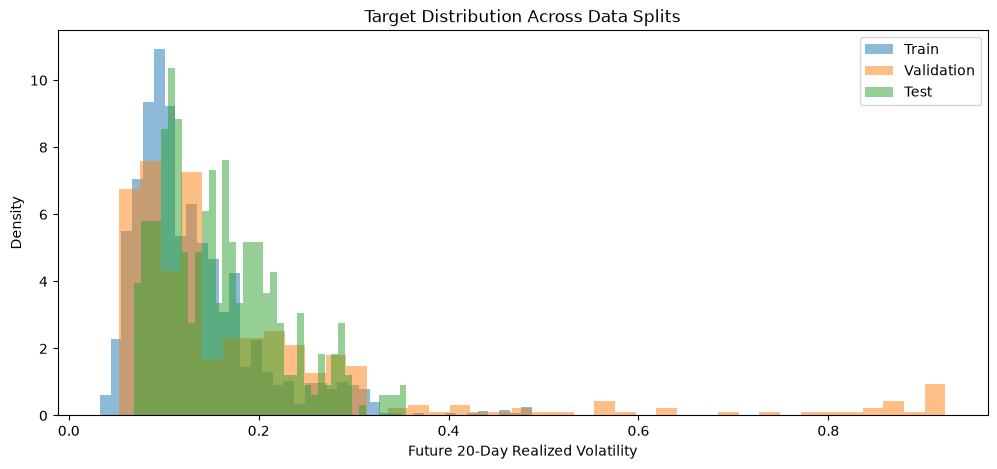

In [257]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(
    train_ml[target],
    bins=40,
    alpha=0.5,
    density=True,
    label="Train"
)

plt.hist(
    val_ml[target],
    bins=40,
    alpha=0.5,
    density=True,
    label="Validation"
)

plt.hist(
    test_ml[target],
    bins=40,
    alpha=0.5,
    density=True,
    label="Test"
)

plt.xlabel("Future 20-Day Realized Volatility")
plt.ylabel("Density")
plt.title("Target Distribution Across Data Splits")
plt.legend()
plt.show()

In [258]:
for name, data in [
    ("Train", train_ml),
    ("Validation", val_ml),
    ("Test", test_ml)
]:
    mae = mean_absolute_error(
        data["future_rv_20d"],
        data["rv_20d"]
    )

    print(f"{name}: {mae:.5f}")

Train: 0.04692
Validation: 0.11197
Test: 0.04901


In [259]:
feature_groups = {
    "SPY": spy_features,
    "SPY + VIX": spy_features + vix_features,
    "SPY + Options": spy_features + options_features,
    "All Features": all_features
}

regularized_models = {}
regularized_results = []
regularized_histories = {}

for group_name, features in feature_groups.items():

    X_train_group = train_ml[features]
    X_val_group = val_ml[features]

    model = XGBRegressor(
        n_estimators=1500,
        max_depth=2,
        learning_rate=0.02,
        min_child_weight=10,
        reg_lambda=20,
        reg_alpha=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        eval_metric="mae",
        early_stopping_rounds=50,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train_group,
        y_train,
        eval_set=[
            (X_train_group, y_train),
            (X_val_group, y_val)
        ],
        verbose=False
    )

    train_pred = model.predict(X_train_group)
    val_pred = model.predict(X_val_group)

    train_mae = mean_absolute_error(y_train, train_pred)
    val_mae = mean_absolute_error(y_val, val_pred)

    regularized_models[group_name] = model
    regularized_histories[group_name] = model.evals_result()

    regularized_results.append({
        "Feature Group": group_name,
        "Train MAE": train_mae,
        "Validation MAE": val_mae,
        "Best Iteration": model.best_iteration,
        "Trees Used": model.best_iteration + 1
    })

regularized_results_df = pd.DataFrame(
    regularized_results
).sort_values("Validation MAE")

display(regularized_results_df)

,Feature Group,Train MAE,Validation MAE,Best Iteration,Trees Used
3,All Features,0.031752,0.087894,126,127
1,SPY + VIX,0.031616,0.088006,141,142
2,SPY + Options,0.033080,0.089484,112,113
0,SPY,0.031877,0.090836,166,167


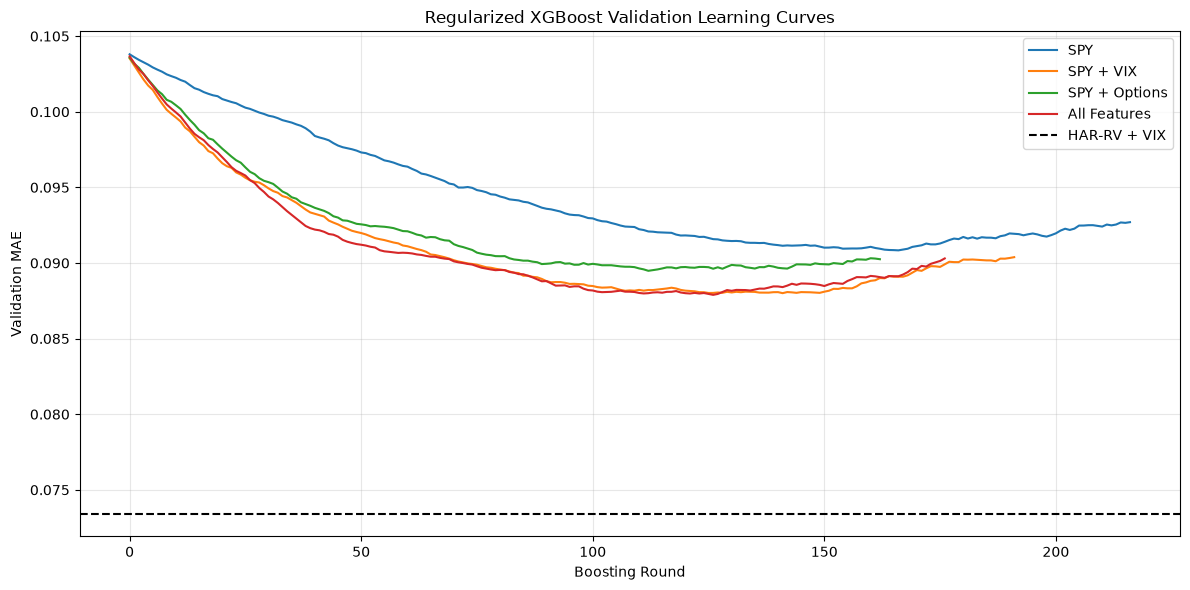

In [260]:
har_val_mae = 0.073434

plt.figure(figsize=(12, 6))

for group_name, history in regularized_histories.items():

    val_mae_history = history["validation_1"]["mae"]

    plt.plot(
        val_mae_history,
        label=group_name
    )

plt.axhline(
    y=har_val_mae,
    color="black",
    linestyle="--",
    label="HAR-RV + VIX"
)

plt.xlabel("Boosting Round")
plt.ylabel("Validation MAE")
plt.title("Regularized XGBoost Validation Learning Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [261]:
ml_results = []

y_test = test_ml[target_col]

# Ridge
ml_results.append(
    evaluate_model(
        y_test,
        ridge_test_pred,
        "Ridge - All Features"
    )
)

# XGBoost
for group_name, features in feature_groups.items():

    model = regularized_models[group_name]

    pred = model.predict(test_ml[features])

    ml_results.append(
        evaluate_model(
            y_test,
            pred,
            f"XGBoost - {group_name}"
        )
    )

ml_results_df = pd.DataFrame(ml_results)

display(ml_results_df.sort_values("MAE"))

,Model,MAE,RMSE,QLIKE
3,XGBoost - SPY + Options,0.043660,0.055272,-2.596910
2,XGBoost - SPY + VIX,0.044591,0.054903,-2.596624
4,XGBoost - All Features,0.044671,0.056052,-2.589291
0,Ridge - All Features,0.045629,0.056971,-2.564312
1,XGBoost - SPY,0.047777,0.059180,-2.536054


In [262]:
joblib.dump(regularized_models, '../models/regularized_xgb_models.pkl')

ml_results_df.to_csv('../data/results/regularized_xgb_validation_results.csv', index=False)